# 대화당 비용 백분위수

**이 노트북에서 할 일**

1. 판정 요청 세 번의 사용량과 요금표로 요청 한 번의 예상 비용을 셉니다.
2. 이 절에서 정한 대화 백 개의 요청 기록을 대화 번호로 묶어 대화당 비용을 셉니다.
3. 대화당 비용의 평균과 백분위수를 가장 가까운 자리 방식으로 셉니다.
4. 가장 긴 대화 하나의 요청 수를 바꿔 평균과 백분위수가 어떻게 달라지는지 봅니다.

**준비물** — 이 절은 프로젝트 맨 위 폴더의 `.env`에 적어 둔 `OPENAI_API_KEY`를 씁니다.
평가 모델 `gpt-5.4-mini`에 보내는 요청은 세 번이고 임베딩 요청은 없습니다.
예상 비용은 미화 0.01달러 아래이고 실제 청구 금액과는 다를 수 있습니다.
읽는 파일은 이 챕터 자료 파일 하나이고 새로 쓰는 파일은 없습니다.
교재 출력을 만든 실행에서는 노트북 전체가 약 5초 만에 끝났습니다.

5절부터 쓰는 대화 백 개의 요청 기록은 실제로 보낸 요청이 아닙니다.
흐름을 보여 주려고 이 절에서 정한 값이고 자료 파일에도 없습니다.
실제로 보내는 요청은 3절의 판정 세 번뿐입니다.

**기준 버전** — 첫 셀에서 LangChain 1.4.0과 langchain-openai 1.6.1을 설치합니다.
키를 읽는 python-dotenv 1.2.3도 함께 설치합니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 이번에 실행하지 않았습니다.

**강의와 실습 범위** — 강의 시간에는 3~8절을 읽습니다.
요청 한 번의 예상 비용을 세고, 대화당 비용을 모아 백분위수로 보는 자리입니다.
9절은 평균보다 비싼 대화를 셉니다.
10절은 값 바꿔 보기이고 9절과 함께 실습 시간에 실행합니다.

실습 폴더 `labs/part4/ch15-evaluation-advanced`에서 `uv sync --locked`를 실행합니다.
그다음 이 폴더의 `.venv` 커널을 고르고 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

![위에서 아래로 읽는 그림으로 초록 상자 요청 기록 420줄 대화 번호 요청 차례 예상 비용 요청 수와 비용은 이 절에서 정한 값에서 파란 상자 cost_by_conversation 대화 번호가 같은 줄끼리 더함을 지나 노란 상자 대화당 비용 목록 대화 백 개로 이어지고, 거기서 왼쪽 파란 상자 nearest_rank 작은 값부터 줄 세워 가장 가까운 자리의 값을 지나 노란 상자 p50 0.003 p95 0.006 p99 0.025로 가며, 견주려고라고 적힌 화살표를 따라 오른쪽 파란 상자 average 모두 더해 백으로 나눔을 지나 노란 상자 평균 0.0042로 가는 그림](attachment:06-1-요청-기록에서-대화당-비용으로.png)

위에서 아래로 읽습니다. 초록 상자는 이 절에서 정한 요청 기록이고, 파란 함수가 대화 번호마다 더해 노란 대화당 비용 목록을 만듭니다.
목록에서 왼쪽으로 가면 백분위수, 「견주려고」 화살표를 따라 오른쪽으로 가면 평균이 나옵니다.
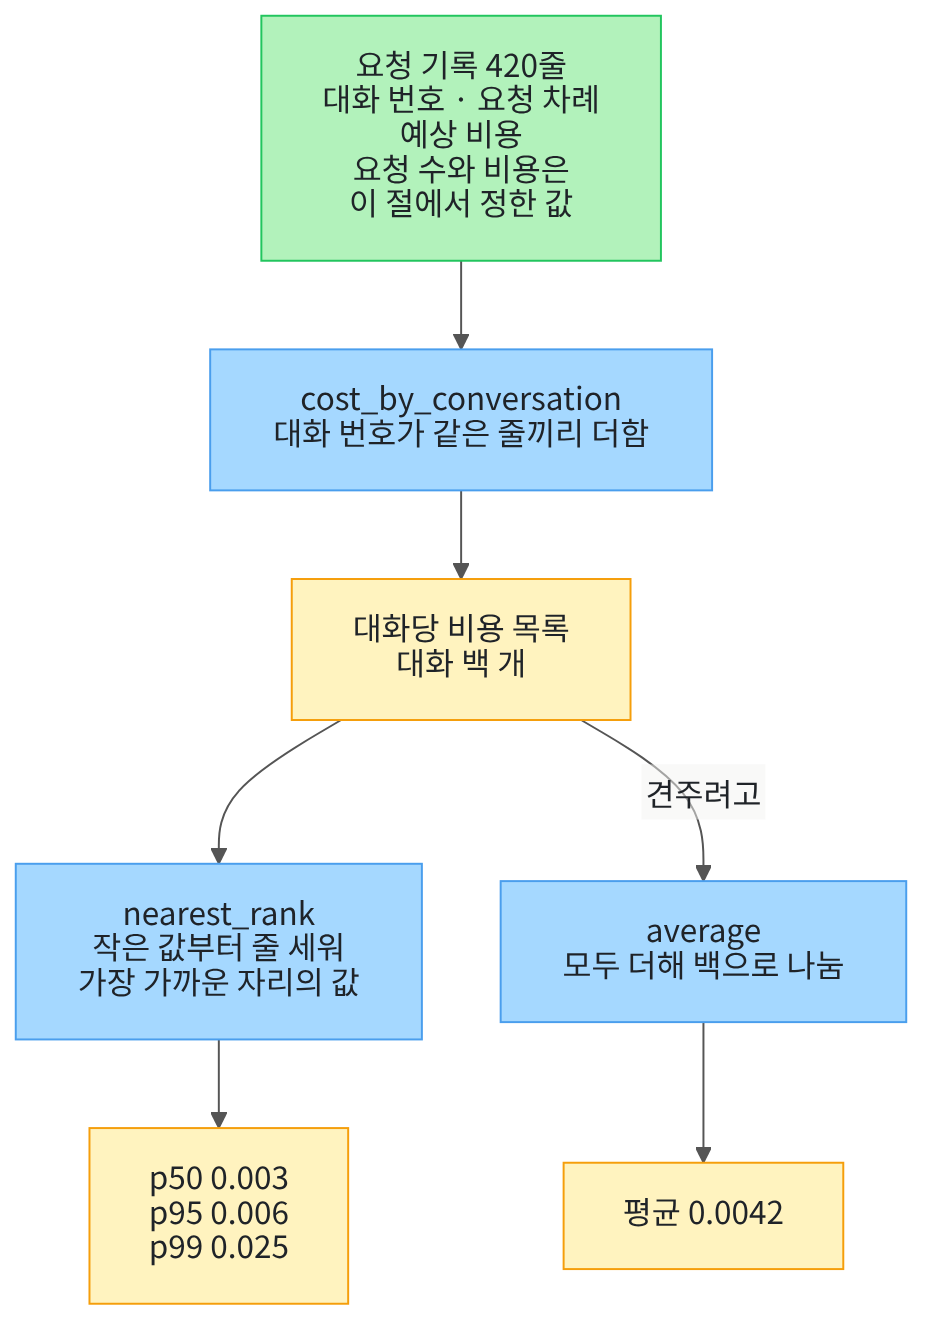

## 1. 준비

첫 셀은 패키지 세 개를 설치하고 설치된 판 번호를 출력합니다.
설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langchain==1.4.0" "langchain-openai==1.6.1" "python-dotenv==1.2.3"
from importlib.metadata import version

print("langchain:", version("langchain"))
print("langchain-openai:", version("langchain-openai"))
print("python-dotenv:", version("python-dotenv"))

Note: you may need to restart the kernel to use updated packages.
langchain: 1.4.0
langchain-openai: 1.6.1
python-dotenv: 1.2.3


**결과 읽기** — 설치가 끝나면 판 번호 세 줄이 보입니다.
출력 줄 `langchain: 1.4.0`과 `langchain-openai: 1.6.1`이 실습 폴더 잠금과 같은 판입니다.
이 노트북의 출력은 2026-09-21에 이 판으로 실행한 결과입니다.

다음 셀은 이 절에서 쓸 이름을 불러오고 앞에서 배운 함수 둘을 도구 파일에서 가져옵니다.
이름 `math`는 Python에 들어 있는 수학 함수 묶음이고, 8절에서 소수를 올릴 때 씁니다.

앞에서 배운 함수는 `rag_tools.py`에 모아 두었습니다. 파일을 열면 코드를 볼 수 있습니다. 노트북과 같은 폴더(`notebooks/`)에 있는 파일입니다.
이 노트북은 02절 `build_judge_prompt()`와 Ch 6 06절 `estimate_cost()`를 가져옵니다.

In [2]:
# 자료 읽기·올림 계산·폴더 확인에 쓸 이름과 모델을 준비하는 이름을 불러옵니다
import json
import math
import os

from langchain.chat_models import init_chat_model

# Ch 15 02절 함수 하나와 Ch 6 06절 함수 하나를 도구 파일에서 가져옵니다
from rag_tools import build_judge_prompt, estimate_cost

print("불러온 이름:", "json", "math", "os", "init_chat_model")

불러온 이름: json math os init_chat_model


**결과 읽기** — 출력 줄 `불러온 이름: json math os init_chat_model`로 이름 네 개를 불러왔습니다.
도구 파일에서 가져온 함수 둘은 출력하지 않습니다.
함수 `estimate_cost`는 Ch 6 06절 본문 그대로 도구 파일에 옮겼고, 인자도 그때와 같습니다.

## 2. 키와 모델 준비

이 절도 02~05절과 같은 평가 모델 `gpt-5.4-mini`를 부릅니다.
모델을 만드는 설정 값도 05절과 같습니다.

API 키가 있는지 확인합니다. `True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


실습에 쓸 모델을 준비합니다.
temperature 값을 0으로 두어도 판정 글과 토큰 수가 매번 같다고 보장하지는 않습니다.

In [4]:
# 실습에 쓸 모델을 준비합니다
model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
)
print("모델 이름:", model.model_name)
print("temperature:", model.temperature)

모델 이름: gpt-5.4-mini
temperature: 0.0


**결과 읽기** — 모델 이름 `gpt-5.4-mini`, temperature `0.0`이 보이면 준비가 끝났습니다.
이 노트북의 출력은 2026-09-21에 이 모델로 실행한 결과입니다.

## 3. 판정 요청 세 번과 사용량

이 절의 앞부분은 요청 한 번에 드는 예상 비용을 실제 요청으로 셉니다.
02~05절과 같은 근거 충실도 판정을 평가 사례 세 건에 한 번씩 보냅니다.

먼저 노트북을 연 자리에서 프로젝트 맨 위를 찾습니다.
01~05절과 같은 자리 찾기 셀입니다.

In [5]:
# 노트북을 어느 폴더에서 열어도 프로젝트 맨 위를 찾게 후보 세 개를 차례로 봅니다
candidates = [".", "../../..", "../../../.."]
root_path = None
for candidate in candidates:
    if os.path.exists(candidate + "/labs/part4/ch15-evaluation-advanced/data"):
        root_path = candidate
        break
print("찾은 프로젝트 맨 위:", root_path)
assert root_path is not None, "notebooks 폴더나 실습 폴더 맨 위에서 노트북을 열어 주세요."

찾은 프로젝트 맨 위: .


**결과 읽기** — 출력 줄 `찾은 프로젝트 맨 위:` 뒤에 점 하나나 위로 올라가는 자리가 보입니다.

다음 셀은 05절과 같은 방법으로 이 챕터 자료 파일을 읽습니다.
사례마다 질문 번호도 모아 둡니다.

In [6]:
# 이 챕터 자료 파일을 읽어 평가 사례 목록을 만들고 질문 번호를 모읍니다(읽기만 합니다)
data_path = root_path + "/labs/part4/ch15-evaluation-advanced/data"
with open(data_path + "/evaluation-cases.json", encoding="utf-8") as file:
    case_file = json.loads(file.read())
cases = case_file["cases"]
case_qids = []
for case in cases:
    case_qids.append(case["qid"])
print("평가 사례 수:", len(cases))
print("질문 번호:", case_qids)

평가 사례 수: 3
질문 번호: ['Q002', 'Q006', 'Q090']


**결과 읽기** — 출력 줄 `평가 사례 수: 3`으로 사례는 세 건입니다.
출력 줄 `질문 번호: ['Q002', 'Q006', 'Q090']`이 판정을 받을 세 사례입니다.

다음 셀은 02절 근거 충실도의 판정 머리글을 다시 적습니다.
05절에서 다시 적은 머리글과 같은 글입니다.

In [7]:
# 02절 근거 충실도의 두 칸 짝과 판정 머리글 rag-judge-v1.0.0을 다시 적습니다
ground_pair = {"답": "response", "근거 문서": "context"}
ground_rule = "답이 근거 문서로 뒷받침되면 1, 아니면 0을 판정하세요."
output_rule = 'JSON만 출력하세요: {"score": 0 또는 1, "reason": "한 문장"}.'
judge_version = "rag-judge-v1.0.0"
judge_head = ground_rule + "\n" + output_rule
print("판 이름:", judge_version)
print("머리글:")
print(judge_head)

판 이름: rag-judge-v1.0.0
머리글:
답이 근거 문서로 뒷받침되면 1, 아니면 0을 판정하세요.
JSON만 출력하세요: {"score": 0 또는 1, "reason": "한 문장"}.


**결과 읽기** — 출력 줄 `판 이름: rag-judge-v1.0.0`은 02절이 붙인 판 이름입니다.
라벨 줄 `머리글:` 아래 두 줄이 기준 문장과 출력 모양입니다.

다음 셀은 세 사례의 판정 요청 글을 만들어 평가 모델에 한 번씩 보냅니다.
응답 객체는 사용량을 읽으려고 질문 번호별로 모아 둡니다.
이 셀에서 모델 요청이 세 번 나갑니다.

In [8]:
# 평가 사례 세 건마다 근거 충실도 판정 요청을 한 번씩 보내고 응답 객체를 질문 번호별로 모읍니다(모델 요청 3번)
replies = {}
print("질문 번호 | 요청 글 글자 수 | 점수")
for case in cases:
    prompt_text = build_judge_prompt(judge_head, ground_pair, case)
    reply = model.invoke(prompt_text)
    replies[case["qid"]] = reply
    verdict = json.loads(reply.text)
    print(case["qid"], "|", len(prompt_text), "|", verdict["score"])

질문 번호 | 요청 글 글자 수 | 점수


Q002 | 3161 | 1


Q006 | 3183 | 1


Q090 | 5093 | 0


**결과 읽기** — 라벨 줄 `질문 번호 | 요청 글 글자 수 | 점수` 아래 세 줄이 세 요청입니다.
줄 `Q002 | 3161`, `Q006 | 3183`, `Q090 | 5093`처럼 요청 글은 근거 문서가 긴 Q090이 가장 깁니다.

이번 실행에서 점수는 Q002 1, Q006 1, Q090 0이었습니다.
02~05절에서 같은 머리글로 받은 점수와 같습니다.
새 커널로 두 번 실행했을 때 세 점수와 요청 글 글자 수는 두 번 모두 같았습니다.

판정 점수가 맞는지는 02~04절에서 봤으니 이 절에서는 다시 따지지 않습니다.
다음 셀은 세 응답 객체의 사용량을 꺼내 봅니다. 새 요청은 보내지 않습니다.

In [9]:
# 세 응답 객체의 사용량에서 입력·캐시 입력·출력 토큰 수를 꺼내 한 줄씩 봅니다(요청 없음)
print("질문 번호 | 입력 토큰 수 | 캐시 입력 토큰 수 | 출력 토큰 수")
for qid in replies:
    usage = replies[qid].usage_metadata
    cache_read = usage["input_token_details"]["cache_read"]
    print(qid, "|", usage["input_tokens"], "|", cache_read, "|", usage["output_tokens"])

질문 번호 | 입력 토큰 수 | 캐시 입력 토큰 수 | 출력 토큰 수
Q002 | 1995 | 1792 | 42
Q006 | 2004 | 1792 | 43
Q090 | 3248 | 2816 | 48


**결과 읽기** — 라벨 줄 `질문 번호 | 입력 토큰 수 | 캐시 입력 토큰 수 | 출력 토큰 수` 아래 세 줄이 세 요청의 사용량입니다.
입력 토큰 수는 `Q002 | 1995`, `Q006 | 2004`, `Q090 | 3248`로 요청 글이 긴 Q090이 가장 많습니다.

이번 실행에서 캐시 입력은 Q002와 Q006이 1792, Q090이 2816토큰이었습니다.
출력 토큰은 차례로 42, 43, 48개였습니다.
새 커널로 두 번 실행했을 때 입력 토큰 수는 같았고, 캐시 입력과 출력 토큰 수는 두 실행에서 달랐습니다.
Ch 6 06절에서 본 것처럼 캐시 입력은 앞부분이 같은 요청을 앞서 보냈을 때 생길 수 있습니다.
이번에 생긴 까닭은 확인하지 않았고, 여러분 실행에서는 0일 수 있습니다.

## 4. 요청 한 번의 예상 비용

요금은 100만 토큰당 달러로 정해져 있습니다. 입력, 캐시 입력, 출력의 요금이 서로 다릅니다.
다음 셀은 Ch 6 06절 요금표를 같은 키 이름과 값으로 다시 적습니다.
2026-09-17에 확인한 모델 mini의 요금입니다.

In [10]:
# Ch 6 06절 요금표(100만 토큰당 달러)를 같은 키 이름과 값으로 다시 적고 확인한 날짜도 적습니다
pricing_date = "2026-09-17"
mini_prices = {"ordinary_input": 0.75, "cached_input": 0.075, "output": 4.50}
print("요금 확인 날짜:", pricing_date)
print("mini 요금:", mini_prices)

요금 확인 날짜: 2026-09-17
mini 요금: {'ordinary_input': 0.75, 'cached_input': 0.075, 'output': 4.5}


**결과 읽기** — 출력 줄 `요금 확인 날짜: 2026-09-17`이 요금을 확인한 날짜입니다.
출력 줄 `mini 요금: {'ordinary_input': 0.75, 'cached_input': 0.075, 'output': 4.5}`가 세 요금입니다.
숫자 4.50은 출력에서 `4.5`로 보입니다. 값은 같습니다.

예상 비용은 토큰 수에 요금을 곱해 더합니다. 입력 토큰에서 캐시 입력을 뺀 나머지를 일반 입력으로 봅니다.
식은 `(일반 입력 × 입력 요금 + 캐시 입력 × 캐시 입력 요금 + 출력 × 출력 요금) ÷ 1000000`입니다.
Ch 6 06절 함수 `estimate_cost()`가 이 식을 계산하고, 이 노트북은 도구 파일에서 가져왔습니다.

함수 본문에는 딕셔너리 메서드 `get()`이 두 번 나옵니다.
메서드 `get(키, 값)`은 키가 있으면 그 키의 값을, 없으면 둘째 인자의 값을 냅니다.
그래서 캐시 입력 칸이 없는 사용량은 캐시 입력을 0으로 셉니다.
다음 셀은 Ch 6 06절 교재 예로 함수를 먼저 확인합니다.

In [11]:
# Ch 6 06절 교재 예 사용량과 사용량이 없는 경우로 도구 파일의 estimate_cost를 확인합니다(요청 없음)
example_usage = {"input_tokens": 100, "output_tokens": 10, "input_token_details": {"cache_read": 40}}
input_rate = mini_prices["ordinary_input"]
cached_rate = mini_prices["cached_input"]
output_rate = mini_prices["output"]
example_cost = estimate_cost(example_usage, input_rate, cached_rate, output_rate)
missing_cost = estimate_cost(None, input_rate, cached_rate, output_rate)
print("교재 예 비용(달러):", round(example_cost, 6))
print("사용량이 없을 때 비용:", missing_cost)
assert round(example_cost, 6) == 0.000093

교재 예 비용(달러): 9.3e-05
사용량이 없을 때 비용: None


**결과 읽기** — 출력 줄 `교재 예 비용(달러): 9.3e-05`는 Ch 6 06절처럼 0.000093달러를 짧게 적은 모양입니다.
출력 줄 `사용량이 없을 때 비용: None`처럼 모르는 사용량은 0달러가 아니라 `None`으로 남습니다.
마지막 줄의 `assert`도 통과했습니다.

교재 예는 입력 100토큰 가운데 캐시 입력이 40, 출력이 10토큰입니다.
식에 넣으면 `(60 × 0.75 + 40 × 0.075 + 10 × 4.50) ÷ 1000000`이고 0.000093입니다.
손으로 정한 예라 결과를 미리 알 수 있어 `assert`로 확인했습니다.

다음 셀은 3절에서 받은 세 요청의 실제 사용량으로 예상 비용을 계산합니다.
캐시 입력 할인 없이 계산한 비용도 나란히 셉니다.
캐시 입력 요금 자리에 입력 요금을 넣는 방법으로, Ch 6 06절에서 쓴 방법입니다.
새 요청은 보내지 않습니다.

In [12]:
# 세 요청의 예상 비용을 계산하고, 캐시 입력 할인 없이 계산한 비용도 나란히 봅니다(요청 없음)
total_cost = 0
print("질문 번호 | 예상 비용(달러) | 캐시 입력 할인 없이(달러)")
for qid in replies:
    usage = replies[qid].usage_metadata
    cost = estimate_cost(usage, input_rate, cached_rate, output_rate)
    no_discount_cost = estimate_cost(usage, input_rate, input_rate, output_rate)
    total_cost = total_cost + cost
    print(qid, "|", round(cost, 8), "|", round(no_discount_cost, 8))
print("세 요청의 예상 비용 합(달러):", round(total_cost, 8))

질문 번호 | 예상 비용(달러) | 캐시 입력 할인 없이(달러)
Q002 | 0.00047565 | 0.00168525
Q006 | 0.0004869 | 0.0016965
Q090 | 0.0007512 | 0.002652
세 요청의 예상 비용 합(달러): 0.00171375


**결과 읽기** — 라벨 줄 `질문 번호 | 예상 비용(달러) | 캐시 입력 할인 없이(달러)` 아래 세 줄이 요청마다의 값입니다.
출력 줄 `세 요청의 예상 비용 합(달러):` 뒤가 이 노트북에서 보낸 요청 세 번의 예상 비용입니다.

이번 실행에서 Q002의 예상 비용은 0.00047565달러였습니다.
사례 Q006은 0.0004869달러, 사례 Q090은 0.0007512달러였고 세 요청 합은 0.00171375달러였습니다.
캐시 입력 할인 없이 계산한 값은 0.00168525, 0.0016965, 0.002652달러로 세 배 넘게 큽니다.

출력 토큰 수가 같다면, 캐시 입력이 0인 실행의 예상 비용은 오른쪽 칸 값과 같습니다.
새 커널로 두 번 실행했을 때 두 칸 값은 모두 두 실행에서 달랐습니다.
캐시 입력과 출력 토큰 수가 요청마다 달라지기 때문이고, 그래서 예상 비용에는 `assert`를 쓰지 않습니다.

이 값은 요금표로 계산한 예상 비용이고 실제 청구 금액을 확인한 것은 아닙니다.

## 5. 대화 비용 목록 만들기

서비스에서 대화 하나에는 요청이 여러 번 들어 있습니다.
05절 방식이면 요청마다 실행 추적이 한 건씩 남습니다.
실행 추적에 대화 번호와 예상 비용 칸을 더하면 이 절의 요청 기록 한 줄이 됩니다.

대화당 비용의 모양을 보려면 대화가 많이 필요합니다.
그러나 자료 파일에는 평가 사례 세 건만 있습니다.
다음 셀은 사례 칸에 대화를 가리키는 칸이 있는지 봅니다.

In [13]:
# 사례 한 건의 칸 이름을 보고 대화를 가리키는 칸이 있는지 확인합니다(자료 파일을 읽기만 합니다)
case_keys = list(cases[0].keys())
print("사례 칸 수:", len(case_keys))
print("사례 칸:")
print(case_keys)
print("대화 번호 칸이 있는가:", "conversation_id" in case_keys)

사례 칸 수: 14
사례 칸:
['qid', 'question', 'gold_doc_ids', 'retrieved_doc_ids', 'context', 'response', 'reference_answer', 'reference_kind', 'answer_model', 'answer_prompt_version', 'judge_raw', 'judge_model', 'judge_placeholder', 'judge_prompt_version']
대화 번호 칸이 있는가: False


**결과 읽기** — 출력 줄 `사례 칸 수: 14`와 라벨 줄 `사례 칸:` 아래 목록이 사례 한 건의 칸 이름입니다.
출력 줄 `대화 번호 칸이 있는가: False`처럼 대화를 가리키는 칸은 없습니다.

그래서 이 절은 대화 목록을 자료 파일에서 읽지 않고 정해서 씁니다.
다음 셀의 두 값은 잰 값이 아니라 흐름을 보여 주려고 이 절에서 정한 값입니다.
요청 한 번 비용은 모든 요청에 같은 둥근 수 0.001달러를 둡니다.
대화마다 요청 수는 요청 수별 대화 수 표로 정합니다.

In [14]:
# 흐름을 보여 주려고 이 절에서 정한 값입니다: 요청 한 번 비용과 요청 수별 대화 수(잰 값이 아닙니다)
request_cost = 0.001
conversation_mix = {2: 30, 3: 35, 4: 20, 6: 10, 10: 3, 25: 1, 60: 1}
print("요청 한 번 비용(달러, 정한 값):", request_cost)
print("요청 수별 대화 수:", conversation_mix)

요청 한 번 비용(달러, 정한 값): 0.001
요청 수별 대화 수: {2: 30, 3: 35, 4: 20, 6: 10, 10: 3, 25: 1, 60: 1}


**결과 읽기** — 출력 줄 `요청 한 번 비용(달러, 정한 값): 0.001`이 모든 요청에 쓸 비용입니다.
출력 줄 `요청 수별 대화 수: {2: 30, 3: 35, 4: 20, 6: 10, 10: 3, 25: 1, 60: 1}`이 대화 구성표입니다.
키는 대화 하나의 요청 수이고 값은 그런 대화의 수입니다.

요청을 두세 번 보낸 대화가 대부분이고, 요청이 25번·60번인 대화가 한 개씩 있습니다.
오래 이어진 대화나 다시 시도가 많았던 대화를 떠올리면 됩니다.
다음 셀은 이 표를 펼쳐 대화 백 개의 요청 수 목록을 만듭니다.

In [15]:
# 요청 수별 대화 수를 펼쳐 대화 백 개의 요청 수 목록을 만듭니다(대화 하나에 요청 수 하나)
request_counts = []
for request_count in conversation_mix:
    # 그 요청 수를 가진 대화의 수만큼 되풀이해 목록에 붙입니다
    for repeat in range(conversation_mix[request_count]):
        request_counts.append(request_count)
print("대화 수:", len(request_counts))
print("앞 다섯 대화의 요청 수:", request_counts[:5])
print("뒤 다섯 대화의 요청 수:", request_counts[-5:])

대화 수: 100
앞 다섯 대화의 요청 수: [2, 2, 2, 2, 2]
뒤 다섯 대화의 요청 수: [10, 10, 10, 25, 60]


**결과 읽기** — 출력 줄 `대화 수: 100`으로 대화는 백 개입니다.
출력 줄 `앞 다섯 대화의 요청 수: [2, 2, 2, 2, 2]`가 목록의 앞쪽입니다.
출력 줄 `뒤 다섯 대화의 요청 수: [10, 10, 10, 25, 60]`이 목록의 뒤쪽입니다.

목록 자리 `[-5:]`는 목록의 뒤 다섯 개를 꺼냅니다.
안쪽 `for`는 대화 수만큼 같은 요청 수를 목록에 붙입니다.
변수 `repeat`은 되풀이할 때 번호를 받기만 하고 다른 곳에 쓰지 않습니다.
다음 셀은 요청 수 목록으로 요청 기록을 만드는 함수입니다.

In [16]:
# 대화마다 번호를 붙이고, 요청 한 번마다 요청 기록 한 줄(대화 번호·요청 차례·예상 비용)을 만듭니다
def make_request_rows(counts, cost):
    rows = []
    for i in range(len(counts)):
        conversation_id = "대화-" + str(i + 1)
        for turn in range(counts[i]):
            rows.append({"대화 번호": conversation_id, "요청 차례": turn + 1, "예상 비용(달러)": cost})
    return rows

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `make_request_rows`는 대화마다 요청 수 목록과 요청 한 번 비용을 받습니다.
대화 번호는 목록 자리 `i`에 1을 더해 `대화-1`부터 붙입니다.
대화마다 요청 수만큼 요청 기록을 한 줄씩 만들어 한 목록에 모아 냅니다.
칸 `요청 차례`는 셈에 쓰지 않고, 한 대화의 요청이 여러 줄로 적힌다는 것을 보여 줍니다.

다음 셀은 이 함수로 대화 백 개의 요청 기록을 만듭니다.

In [17]:
# 대화 백 개의 요청 기록을 만들고 줄 수와 첫 줄·마지막 줄을 봅니다(모델 요청 없음)
request_rows = make_request_rows(request_counts, request_cost)
print("요청 기록 줄 수:", len(request_rows))
print("첫 줄:", request_rows[0])
print("마지막 줄:", request_rows[-1])

요청 기록 줄 수: 420
첫 줄: {'대화 번호': '대화-1', '요청 차례': 1, '예상 비용(달러)': 0.001}
마지막 줄: {'대화 번호': '대화-100', '요청 차례': 60, '예상 비용(달러)': 0.001}


**결과 읽기** — 출력 줄 `요청 기록 줄 수: 420`으로 요청 기록은 420줄입니다.
출력 줄 `첫 줄:`과 `마지막 줄:` 뒤 딕셔너리가 요청 기록 한 줄의 모양입니다.
마지막 줄은 `'대화 번호': '대화-100'`이고 `'요청 차례': 60`입니다.

420은 대화 백 개의 요청 수를 모두 더한 수입니다.
실제 서비스라면 이 줄마다 4절처럼 사용량으로 셈한 예상 비용이 적힙니다.
이 목록은 모든 줄에 정한 값 0.001달러를 적었습니다.

## 6. 대화 번호로 묶기

요청 기록은 요청 한 번이 한 줄입니다.
대화당 비용을 보려면 대화 번호가 같은 줄끼리 비용을 더합니다.
다음 셀은 대화 번호마다 비용을 더하는 함수입니다.

In [18]:
# 요청 기록 목록을 대화 번호로 묶어 대화마다 예상 비용을 더합니다(더할 때마다 여섯째 자리에서 반올림합니다)
def cost_by_conversation(rows):
    totals = {}
    for row in rows:
        key = row["대화 번호"]
        if key not in totals:
            totals[key] = 0
        totals[key] = round(totals[key] + row["예상 비용(달러)"], 6)
    return totals

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `cost_by_conversation`은 요청 기록 목록을 처음부터 끝까지 봅니다.
처음 보는 대화 번호이면 그 번호의 합을 0으로 두고 시작합니다.
그다음 그 줄의 예상 비용을 더합니다.
결과는 대화 번호가 키이고 비용 합이 값인 딕셔너리입니다.

더할 때마다 `round(…, 6)`으로 여섯째 자리에서 반올림합니다.
소수를 여러 번 더하면 0.010000000000000002처럼 아주 작은 오차가 붙기 때문입니다.
다음 셀은 이 함수로 대화 번호별 비용을 만들고 목록으로 옮깁니다.

In [19]:
# 대화 번호별 비용을 만들고 값만 목록으로 옮긴 뒤 첫 대화와 마지막 대화의 비용을 봅니다
conversation_totals = cost_by_conversation(request_rows)
conversation_costs = list(conversation_totals.values())
print("대화 수:", len(conversation_costs))
print("대화-1 비용(달러):", conversation_totals["대화-1"])
print("대화-100 비용(달러):", conversation_totals["대화-100"])

대화 수: 100
대화-1 비용(달러): 0.002
대화-100 비용(달러): 0.06


**결과 읽기** — 출력 줄 `대화 수: 100`으로 대화 번호 백 개의 비용이 모였습니다.
출력 줄 `대화-1 비용(달러): 0.002`는 요청 두 번의 비용입니다.
출력 줄 `대화-100 비용(달러): 0.06`은 요청 60번의 비용입니다.

한 대화의 비용은 요청 수 × 0.001달러와 같습니다. 요청 한 번 비용을 모두 같게 정했기 때문입니다.
목록 `conversation_costs`에는 대화 백 개의 비용이 대화 번호 차례로 들어 있습니다.

## 7. 줄 세우기와 평균

평균은 값을 모두 더해 값의 수로 나눈 값입니다.
다음 셀은 목록의 평균을 내는 함수입니다. 10절에서 한 번 더 쓰려고 함수로 묶습니다.

In [20]:
# 값 목록을 모두 더해 값의 수로 나눈 평균을 냅니다(여섯째 자리에서 반올림합니다)
def average(values):
    total = 0
    for value in values:
        total = total + value
    return round(total / len(values), 6)

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `average`는 값을 하나씩 더해 합을 만들고 값의 수로 나눕니다.
결과는 여섯째 자리에서 반올림합니다.

다음 셀은 대화 비용을 작은 값부터 줄 세우고 평균을 냅니다.
Ch 6 06절에서 쓴 함수 `sorted()`는 값을 작은 것부터 줄 세운 새 목록을 만듭니다.
원래 목록 `conversation_costs`의 차례는 그대로 남습니다.

In [21]:
# 대화 비용을 작은 값부터 줄 세우고 가장 싼 다섯 대화·가장 비싼 다섯 대화와 평균을 봅니다
ordered_costs = sorted(conversation_costs)
mean_cost = average(conversation_costs)
print("가장 싼 다섯 대화(달러):", ordered_costs[:5])
print("가장 비싼 다섯 대화(달러):", ordered_costs[-5:])
print("대화당 평균 비용(달러):", mean_cost)

가장 싼 다섯 대화(달러): [0.002, 0.002, 0.002, 0.002, 0.002]
가장 비싼 다섯 대화(달러): [0.01, 0.01, 0.01, 0.025, 0.06]
대화당 평균 비용(달러): 0.0042


**결과 읽기** — 출력 줄 `가장 싼 다섯 대화(달러): [0.002, 0.002, 0.002, 0.002, 0.002]`가 줄의 앞쪽입니다.
출력 줄 `가장 비싼 다섯 대화(달러): [0.01, 0.01, 0.01, 0.025, 0.06]`이 줄의 끝쪽입니다.
출력 줄 `대화당 평균 비용(달러): 0.0042`가 대화 백 개의 평균입니다.

줄 끝의 0.025달러와 0.06달러는 앞쪽 대화보다 열 배 넘게 큽니다.
다음 셀은 비용이 같은 대화끼리 몇 개인지 세어 줄 전체의 모양을 봅니다.

In [22]:
# 줄 세운 목록을 차례로 보며 비용이 같은 대화끼리 몇 개인지 셉니다
cost_counts = {}
for cost in ordered_costs:
    if cost not in cost_counts:
        cost_counts[cost] = 0
    cost_counts[cost] = cost_counts[cost] + 1
print("대화당 비용: 대화 수 =", cost_counts)

대화당 비용: 대화 수 = {0.002: 30, 0.003: 35, 0.004: 20, 0.006: 10, 0.01: 3, 0.025: 1, 0.06: 1}


**결과 읽기** — 출력 줄 `대화당 비용: 대화 수 = {0.002: 30, 0.003: 35, 0.004: 20, 0.006: 10, 0.01: 3, 0.025: 1, 0.06: 1}`이 줄 전체의 모양입니다.
0.004달러 이하인 대화가 85개이고, 0.01달러 이상인 대화는 다섯 개뿐입니다.

대부분의 값은 작고 드물게 큰 값이 몇 개 있어 줄 끝이 길게 늘어진 모양을 긴 꼬리(long tail)라고 부릅니다.
장바구니 대부분은 물건 몇 개인데 가끔 수레 가득 사는 손님이 있는 모양과 같습니다.
이 절에서는 비용이 0.025달러와 0.06달러인 두 대화가 긴 꼬리입니다.

## 8. 백분위수

평균 하나로는 줄의 어디쯤에 대화가 몰려 있는지 알 수 없습니다.
백분위수(percentile)는 값을 줄 세웠을 때 전체의 몇 퍼센트가 그 값 이하에 드는지 나타내는 값입니다.
키 순서로 선 학생 100명에서 95번째 학생의 키가 95번째 백분위수입니다. 학생 95명이 그 키 이하입니다.
이 절에서는 함수 `nearest_rank`가 대화 비용 목록에서 찾는 값입니다.

백분위수를 세는 방식은 여러 가지이고, 이 절은 가장 가까운 자리 방식(nearest rank)으로 셉니다.
자리는 백분위 × 값의 수 ÷ 100을 계산해 올린 정수이고, 줄에서 그 자리의 값을 그대로 고릅니다.
함수 `math.ceil()`은 소수점 아래가 조금이라도 있으면 올려서 정수로 만듭니다.
다음 셀은 이 방식을 함수 하나로 적습니다.

In [23]:
# 값 목록을 작은 값부터 줄 세우고 가장 가까운 자리 방식으로 백분위수 하나를 찾습니다
def nearest_rank(values, percent):
    ordered = sorted(values)
    rank = math.ceil(percent * len(ordered) / 100)
    return ordered[rank - 1]

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `nearest_rank`는 값 목록과 백분위를 받아 먼저 목록을 줄 세웁니다.
자리 `rank`는 1부터 세지만 목록 자리는 0부터 세므로 `rank - 1` 자리의 값을 꺼냅니다.

다음 셀은 손으로 적은 작은 예 값 다섯 개로 함수를 확인합니다.
값이 정해져 있어 결과를 미리 알 수 있으므로 `assert`로 확인합니다.

In [24]:
# 손으로 적은 작은 예 값 다섯 개로 함수를 확인합니다(미리 정한 값이라 assert로 확인합니다)
small_values = [5, 1, 4, 2, 3]
print("20번째 백분위수:", nearest_rank(small_values, 20))
print("50번째 백분위수:", nearest_rank(small_values, 50))
print("95번째 백분위수:", nearest_rank(small_values, 95))
assert nearest_rank(small_values, 20) == 1
assert nearest_rank(small_values, 50) == 3
assert nearest_rank(small_values, 95) == 5

20번째 백분위수: 1
50번째 백분위수: 3
95번째 백분위수: 5


**결과 읽기** — 출력 줄 `20번째 백분위수: 1`, `50번째 백분위수: 3`, `95번째 백분위수: 5`가 세 값입니다.
세 줄의 `assert`도 모두 통과했습니다.

값 다섯 개를 줄 세우면 1, 2, 3, 4, 5입니다.
20번째 백분위수의 자리는 20 × 5 ÷ 100 = 1이라 첫째 값 1입니다.
50번째 백분위수의 자리는 2.5를 올린 3이라 셋째 값 3이고, 이 값이 가운데 값입니다.
95번째 백분위수의 자리는 4.75를 올린 5라 가장 큰 값 5입니다.
값이 적으면 높은 백분위수가 가장 큰 값과 같아집니다.

Ch 6 06절의 가운데 값도 값 세 개에서 둘째 값이었습니다.
이 방식으로 세어도 1.5를 올린 둘째 자리라 같습니다.
이 절은 50번째 백분위수를 가운데 값으로 부르고, 95번째는 p95처럼 줄여 적습니다.
다음 셀은 대화 백 개의 비용에서 세 백분위수를 찾습니다.

In [25]:
# 대화 백 개의 비용에서 50번째·95번째·99번째 백분위수를 찾아 평균·가장 큰 값과 나란히 봅니다
print("구분 | 대화당 비용(달러)")
for percent in [50, 95, 99]:
    value = nearest_rank(conversation_costs, percent)
    print("p" + str(percent), "|", value)
print("평균 |", mean_cost)
print("가장 큰 값 |", ordered_costs[-1])

구분 | 대화당 비용(달러)
p50 | 0.003
p95 | 0.006
p99 | 0.025
평균 | 0.0042
가장 큰 값 | 0.06


**결과 읽기** — 라벨 줄 `구분 | 대화당 비용(달러)` 아래 다섯 줄이 세 백분위수와 평균, 가장 큰 값입니다.
출력 줄 `p50 | 0.003`이 가운데 값이고 `평균 | 0.0042`보다 작습니다.
출력 줄 `p95 | 0.006`은 대화 95개가 0.006달러 이하라는 뜻입니다.
출력 줄 `p99 | 0.025`와 `가장 큰 값 | 0.06`은 줄 끝의 두 대화입니다.

대화가 100개라 95번째 백분위수의 자리는 95 × 100 ÷ 100 = 95, 곧 95번째 대화입니다.
99번째 백분위수는 99번째 대화이고, 가장 비싼 100번째 대화는 세 백분위수 어디에도 들지 않았습니다.
평균은 가운데 값보다 크고 95번째 백분위수보다 작았습니다.

## 9. 평균보다 비싼 대화

평균 0.0042달러를 보통 대화의 비용으로 읽어도 될까요?
다음 셀은 평균보다 비싼 대화와 평균 이하인 대화를 셉니다.
가장 비싼 대화가 가운데 값의 몇 배인지도 봅니다.

In [26]:
# 평균보다 비싼 대화와 평균 이하인 대화를 세고, 가장 비싼 대화가 가운데 값의 몇 배인지 봅니다
middle_cost = nearest_rank(conversation_costs, 50)
above_count = 0
for cost in conversation_costs:
    if cost > mean_cost:
        above_count = above_count + 1
print("평균보다 비싼 대화 수:", above_count)
print("평균 이하인 대화 수:", len(conversation_costs) - above_count)
print("가장 비싼 대화 ÷ 가운데 값:", round(ordered_costs[-1] / middle_cost, 1))

평균보다 비싼 대화 수: 15
평균 이하인 대화 수: 85
가장 비싼 대화 ÷ 가운데 값: 20.0


**결과 읽기** — 출력 줄 `평균보다 비싼 대화 수: 15`와 `평균 이하인 대화 수: 85`가 두 무리의 대화 수입니다.
출력 줄 `가장 비싼 대화 ÷ 가운데 값: 20.0`으로 가장 비싼 대화는 가운데 값의 20배입니다.

대화 100개 가운데 85개가 평균 이하였습니다.
그래서 평균을 보통 대화의 비용으로 읽으면 실제보다 크게 봅니다.
평균은 대화 수를 곱해 비용 합을 셀 때 쓰고, 대화 비용이 퍼진 모양은 백분위수로 봅니다.

## 10. 값 바꿔 보기 · 가장 긴 대화의 요청 수

바꿀 값은 가장 긴 대화 하나의 요청 수입니다. 대화-100의 요청 수 60을 120으로 바꿉니다.
다시 시도가 겹쳐 요청이 두 배로 늘었다고 해 봅니다.
나머지 대화 아흔아홉 개와 요청 한 번 비용은 그대로입니다.

실행 전에 예상해 봅니다.
비용 합이 0.06달러 늘어 평균은 0.0006달러 오를 것입니다.
세 백분위수는 100번째 대화를 고르지 않으므로 그대로일 것입니다.

In [27]:
# 바꿀 값은 대화-100의 요청 수 하나입니다: 60번을 120번으로 바꾼 복사본으로 다시 셉니다(모델 요청 없음)
changed_counts = request_counts.copy()
changed_counts[-1] = 120
changed_rows = make_request_rows(changed_counts, request_cost)
changed_totals = cost_by_conversation(changed_rows)
changed_costs = list(changed_totals.values())
print("바꾼 대화의 요청 수:", request_counts[-1], "→", changed_counts[-1])
print("대화-100 비용(달러):", conversation_totals["대화-100"], "→", changed_totals["대화-100"])

바꾼 대화의 요청 수: 60 → 120
대화-100 비용(달러): 0.06 → 0.12


**결과 읽기** — 출력 줄 `바꾼 대화의 요청 수: 60 → 120`이 바꾼 값입니다.
출력 줄 `대화-100 비용(달러): 0.06 → 0.12`로 그 대화의 비용이 두 배가 되었습니다.
목록의 `copy()`는 04절 딕셔너리 `copy()`처럼 복사본을 만들어 원래 목록을 그대로 둡니다.

다음 셀은 원래 목록과 바꾼 목록의 평균과 세 백분위수를 나란히 봅니다.

In [28]:
# 원래 목록과 바꾼 목록의 평균과 세 백분위수를 한 줄씩 나란히 봅니다
print("구분 | 원래 목록 | 바꾼 목록")
print("평균 |", mean_cost, "|", average(changed_costs))
for percent in [50, 95, 99]:
    before_value = nearest_rank(conversation_costs, percent)
    after_value = nearest_rank(changed_costs, percent)
    print("p" + str(percent), "|", before_value, "|", after_value)

구분 | 원래 목록 | 바꾼 목록
평균 | 0.0042 | 0.0048
p50 | 0.003 | 0.003
p95 | 0.006 | 0.006
p99 | 0.025 | 0.025


**결과 읽기** — 라벨 줄 `구분 | 원래 목록 | 바꾼 목록` 아래 네 줄이 두 목록의 값입니다.
출력 줄 `평균 | 0.0042 | 0.0048`처럼 평균만 올랐습니다.
출력 줄 `p50 | 0.003 | 0.003`, `p95 | 0.006 | 0.006`, `p99 | 0.025 | 0.025`는 그대로입니다.

예상대로 평균은 0.0006달러 올랐고 세 백분위수는 바뀌지 않았습니다.
드문 큰 값 하나가 커지면 평균은 따라 움직이지만 백분위수는 그대로일 수 있습니다.
그래서 대화당 비용을 적을 때는 평균과 백분위수를 함께 적습니다.

## 정리

1. 판정 요청 세 번의 사용량과 요금표로 요청 한 번의 예상 비용을 셌습니다.
2. 이 절에서 정한 요청 기록을 대화 번호로 묶어 대화 백 개의 비용 목록을 만들었습니다.
3. 정한 목록에서 평균은 가운데 값보다 컸고, 드문 큰 값을 키우자 평균만 올랐습니다.

07절에서는 같은 사례로 이전 판과 이후 판을 견주는 회귀 스위트를 봅니다.